# IMPORTING THE LIBRARIES

In [1]:
import torch

In [2]:
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision import datasets
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

# Downloading dataset from torch vision

In [3]:
train_dataset=datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Checking the dataset

In [4]:
print("Number of training images: ",len(train_dataset))

Number of training images:  60000


In [5]:
image,label=train_dataset[0]

print("Image shape: ",image.shape)
print("Label: ",label)

Image shape:  torch.Size([1, 28, 28])
Label:  9


# Displaying the image

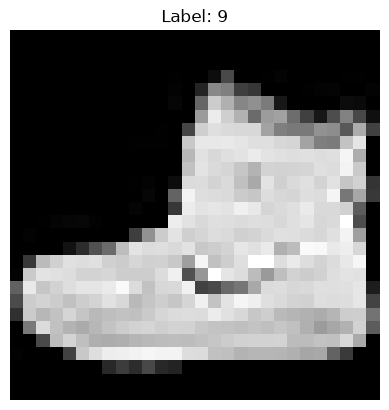

In [6]:
plt.imshow(image.squeeze(),cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

# class names

In [7]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [8]:
print("Label: ",label)
print("Clothing category: ",class_names[label])

Label:  9
Clothing category:  Ankle boot


# Pixel values 

In [9]:
print(image)

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
          0.2863, 0.0000, 0.0000, 0.0039, 0.0157, 0.0000,

In [10]:
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
print("Data type:", image.dtype)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: torch.float32


# Creating batches using DataLoader

In [11]:
train_loader=DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

In [12]:
train_loader

In [13]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


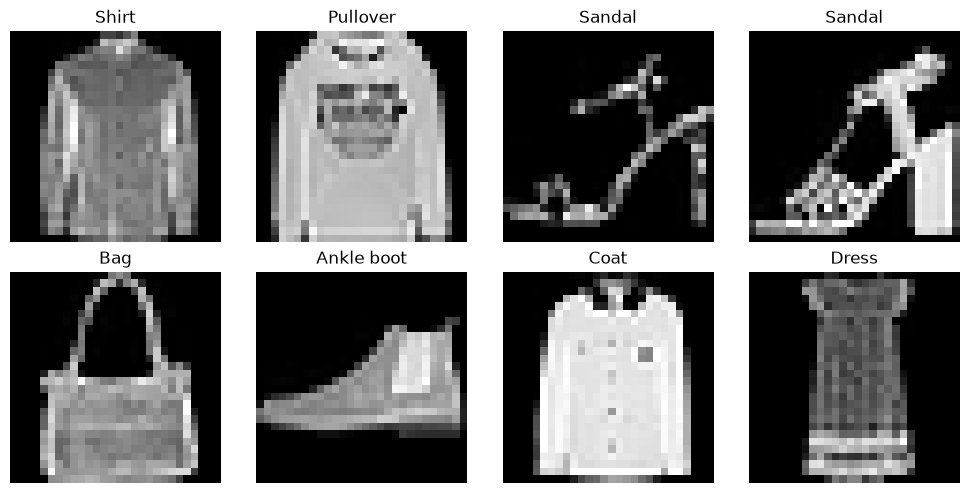

In [14]:
fig,axes=plt.subplots(2,4,figsize=(10,5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(),cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
    
plt.tight_layout()
plt.show()

# Building the neural network

## It initializes these parameters(w and b) using a method based on Kaiming uniform initialization

In [15]:
class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.network=nn.Sequential(
            nn.Flatten(),# this forms a 1D vector of size 784
            nn.Linear(784,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,10)
        )
    
    def forward(self,x):
        return self.network(x)

# Creating the model and pass images through it.

In [16]:
model=FashionClassifier()

In [17]:
outputs=model(images)

In [18]:
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [19]:
print("Output scores:", outputs[0])

Output scores: tensor([ 0.0884, -0.0869,  0.1107,  0.1124,  0.1137,  0.0480,  0.0259,  0.0975,
        -0.0284,  0.0299], grad_fn=<SelectBackward0>)


In [20]:
predicted_class = outputs[0].argmax()

# below is the illustration of randomly initialized weights before training

In [21]:
print("Predicted class number:", predicted_class.item())
print("Predicted category:", class_names[predicted_class.item()])

Predicted class number: 4
Predicted category: Coat


In [22]:
print("Actual:", class_names[labels[0].item()])

Actual: Shirt


# Defining the loss function

The loss function measures how wrong the model is

In [23]:
criterion=nn.CrossEntropyLoss()

# The optimizer updates the model's weights to reduce that error.

In [24]:
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [29]:
loss=criterion(outputs,labels)

loss.backward()
optimizer.step()

print("Loss:", loss.item())

Loss: 2.301994800567627


In [31]:
model.train()
total_loss=0

for images,labels in train_loader:
    optimizer.zero_grad()
    
    outputs = model(images) 
    loss=criterion(outputs,labels)
    
    loss.backward()
    optimizer.step()
    
    total_loss+=loss.item()
    
average_loss=total_loss / len(train_loader)

print("Average training loss: ",average_loss)

Average training loss:  0.5712099458172377


# Checking accuracy

In [ ]:

model.eval()    #switches the model to evaluation mode.

correct=0
total=0

with torch.no_grad():       # disables gradient tracking because we aren't training here.
    for images,labels in train_loader:
        outputs=model(images)
        predictions=outputs.argmax(dim=1)  #selects the highest-scoring class for each image.
        
        correct+=(predictions==labels).sum().item()
        total+=labels.size(0)
        
accuracy=100* correct/total

print("Training accuracy is: ",accuracy)

Training accuracy is:  85.10833333333333


In [35]:
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Number of test images:", len(test_dataset))

Number of test images: 10000


In [36]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"Test accuracy: {test_accuracy:.2f}%")

Test accuracy: 83.71%


In [37]:
for epoch in range(4):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch + 2}/5, Loss: {total_loss / len(train_loader):.4f}")

Epoch 2/5, Loss: 0.3965
Epoch 3/5, Loss: 0.3506
Epoch 4/5, Loss: 0.3255
Epoch 5/5, Loss: 0.3047


In [38]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Final test accuracy: {100 * correct / total:.2f}%")

Final test accuracy: 86.70%


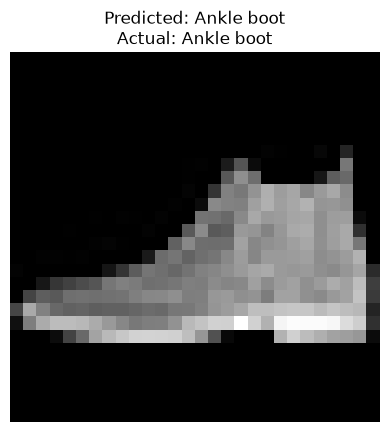

In [39]:
import matplotlib.pyplot as plt

model.eval()

image, actual_label = test_dataset[0]

with torch.no_grad():
    output = model(image.unsqueeze(0))
    predicted_label = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Actual: {class_names[actual_label]}"
)
plt.axis("off")
plt.show()

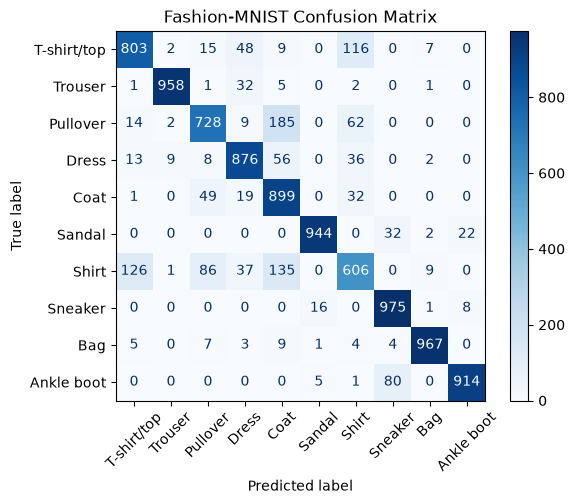

In [42]:
import sklearn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45, cmap="Blues")
plt.title("Fashion-MNIST Confusion Matrix")
plt.show()

In [43]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

 T-shirt/top     0.8339    0.8030    0.8181      1000
     Trouser     0.9856    0.9580    0.9716      1000
    Pullover     0.8143    0.7280    0.7687      1000
       Dress     0.8555    0.8760    0.8656      1000
        Coat     0.6926    0.8990    0.7824      1000
      Sandal     0.9772    0.9440    0.9603      1000
       Shirt     0.7055    0.6060    0.6520      1000
     Sneaker     0.8937    0.9750    0.9326      1000
         Bag     0.9778    0.9670    0.9723      1000
  Ankle boot     0.9682    0.9140    0.9403      1000

    accuracy                         0.8670     10000
   macro avg     0.8704    0.8670    0.8664     10000
weighted avg     0.8704    0.8670    0.8664     10000

